# Gentrification — Measuring a Concept the Data Cannot Resolve

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year, Zillow 2026-08, FRED (pinned)

Every notebook before this one asked whether an arithmetic was right. This one asks a prior
question: **can these sources address the concept at all?**

Gentrification is a neighbourhood process — reinvestment and demographic change in a previously
disinvested area, at the scale of a few blocks. The finest housing-price geography assembled here
is the **county**. That mismatch is not a limitation to note in passing and then work around; it
is the central fact, and the notebook is organised around establishing it rather than burying it.

Three things are established, in order, before any measure is computed:

1. **What the sample actually is.** Long-run home-value coverage is not the United States. It is
   32% of counties — which happen to hold 72% of occupied housing units.
2. **How much of the headline number is inflation.** Roughly three-quarters of it.
3. **How much the answer depends on a definition nobody has agreed.** Two equally defensible
   framings, given identical thresholds, agree on under a third of the counties they name.

Then the measure is built, scoped explicitly, and the thing it cannot be is said plainly.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Separate** a construct from its operationalisation, and recognise when a dataset's geographic
   grain cannot resolve the process being named.
2. **Trace** a coverage cascade end to end, and **weight** it two ways — by unit and by population —
   because those give opposite impressions of the same sample.
3. **Deflate** a long nominal series, and establish how much of a headline change is price level
   rather than relative movement.
4. **Justify** a deflator choice: why CPI excluding shelter is the defensible one for housing, and
   what deflation can and cannot change about a ranking.
5. **Compare** two non-nested operational definitions on identical data and quantify their
   disagreement with a set-overlap statistic.
6. **State** what a measure is not, in the artifact itself, at the same prominence as what it is.

## Prerequisites

**Knowledge.** D27 rent burden (ACS housing tables, the `Not computed` denominator), D16
(coverage and rank stability). Familiarity with price indices is useful but is built up here.

**Setup.** `CENSUS_API_KEY` and `FRED_API_KEY` in the environment or in the file
`KRL_SECRETS_PATH` points at. The pinned Zillow CSVs must be present — see
`data/zillow/2026-08/SOURCES.md`. They are deliberately **not** in version control; the manifest
reproduces the acquisition.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

| Source | What | Role |
|---|---|---|
| **Zillow ZHVI**, county, 2026-08 release | Home value index, monthly, 2000-01 → 2026-07 | the price signal |
| **Zillow ZORI**, county, 2026-08 release | Observed rent index, monthly, 2015-01 → 2026-07 | rent cross-check (43% coverage) |
| **ACS 2023 5-Year** `B19013_001E`, `B25003_001E` | Median household income; occupied units | baseline condition, and population weights |
| **FRED** `CPIAUCSL` | CPI-U, all items | conventional deflator |
| **FRED** `CUUR0000SA0L2` | CPI-U **less shelter** | the defensible deflator here |

**On the two deflators.** Shelter is roughly a third of the CPI basket. Deflating house prices by
an index that contains housing is partly circular — it removes some of the very movement being
measured. `CUUR0000SA0L2` excludes shelter and is the standard way around this. Both are computed
so the difference is visible rather than asserted.

**The Zillow files are pinned by SHA-256.** Zillow overwrites its downloads in place each release,
so "the ZHVI file" is not an identifier. `BulkFileSource` refuses to load bytes that do not match
the pin recorded in the manifest.

In [1]:
"""Configuration. Both definitions and every threshold are declared here, not inline."""
from __future__ import annotations

import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); _REPO = _cand; break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import fetch_acs, fetch_fred, DataAccessError
from krl_tutorials_data.connectors import BulkFileSource, frame_from_bulk_file

ACS_VINTAGE = 2023
ZILLOW_RELEASE = "2026-08"
BASELINE_MONTH = "2000-01-31"
LATEST_MONTH = "2026-07-31"

# The shared skeleton of every operational definition in the literature: a
# baseline disadvantage condition, and a subsequent change condition. What the
# literature does NOT agree on is the reference population for either.
INCOME_PERCENTILE = 40     # "previously disadvantaged": at or below this
GROWTH_PERCENTILE = 60     # "subsequently appreciating": at or above this
MIN_COUNTIES_PER_STATE = 5  # below this a within-state percentile is meaningless

DEFLATORS = {
    "CPIAUCSL": "CPI-U, all items (contains shelter; partly circular here)",
    "CUUR0000SA0L2": "CPI-U less shelter (the defensible choice for housing)",
}

ZILLOW_DIR = _REPO / "data" / "zillow" / ZILLOW_RELEASE
ZHVI_FILE = "County_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"

pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"ACS vintage       : {ACS_VINTAGE} 5-Year")
print(f"Zillow release    : {ZILLOW_RELEASE} (pinned by SHA-256)")
print(f"Window            : {BASELINE_MONTH} to {LATEST_MONTH}")
print(f"Definition        : income <= p{INCOME_PERCENTILE}, growth >= p{GROWTH_PERCENTILE}")
print(f"Deflators         : {len(DEFLATORS)}")
for _c, _d in DEFLATORS.items():
    print(f"  {_c:<16} {_d}")

ACS vintage       : 2023 5-Year
Zillow release    : 2026-08 (pinned by SHA-256)
Window            : 2000-01-31 to 2026-07-31
Definition        : income <= p40, growth >= p60
Deflators         : 2
  CPIAUCSL         CPI-U, all items (contains shelter; partly circular here)
  CUUR0000SA0L2    CPI-U less shelter (the defensible choice for housing)


### The construct, and why it is not a detail

There is no single operational definition of gentrification. The measures in use share a skeleton —
*a baseline disadvantage condition, then a subsequent change condition* — and differ on nearly
everything else: which disadvantage (income, education, rent burden, housing age), which change
(value, rent, demographic composition), what the reference population is (national, metro, city),
and where the thresholds sit.

Every one of those choices is defensible. That is the problem: the result is a classification whose
membership depends on decisions the analyst makes, so the decisions have to be visible.

And all of them are defined at **neighbourhood** scale. The literature works in census tracts
because that is roughly the size of the thing. This notebook has counties.

In [2]:
try:
    zhvi, prov_zhvi = frame_from_bulk_file(
        BulkFileSource(
            path=ZILLOW_DIR / ZHVI_FILE,
            publisher="Zillow Research",
            dataset="ZHVI, All Homes (SFR/Condo), smoothed & seasonally adjusted, county",
            vintage=f"{ZILLOW_RELEASE} release (series through 2026-07)",
            retrieved_on=date(2026, 9, 13),
            sha256="8ea53a5461073e62b1d7f0eb216290954246f56ba344a227956665ab19c2b271",
            terms_url="https://www.zillow.com/corporate/terms-of-use/",
        ),
        loader=lambda p: pd.read_csv(p, low_memory=False),
        expected_columns={
            "RegionName": "county name",
            "StateName": "state postal abbreviation",
            "StateCodeFIPS": "state FIPS",
            "MunicipalCodeFIPS": "county FIPS within state",
            BASELINE_MONTH: "ZHVI at the baseline month",
            LATEST_MONTH: "ZHVI at the latest published month",
        },
    )
except DataAccessError as exc:
    print("HALTED - the pinned Zillow file could not be loaded.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nSee data/zillow/2026-08/SOURCES.md. No synthetic fallback exists by design.")
    raise

zhvi["fips"] = (zhvi.StateCodeFIPS.astype("Int64").astype(str).str.zfill(2)
                + zhvi.MunicipalCodeFIPS.astype("Int64").astype(str).str.zfill(3))
print(f"ZHVI rows: {len(zhvi):,}")
print()
print(prov_zhvi.render())

ZHVI rows: 3,071

Source      : Zillow Research - ZHVI, All Homes (SFR/Condo), smoothed & seasonally adjusted, county (2026-08 release (series through 2026-07))
Vintage     : 2026-08 release (series through 2026-07)  (pinned)
Endpoint    : file://data/zillow/2026-08/County_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv
Retrieved   : 2026-09-18T12:16:50+00:00
Shape       : 3071 rows x 328 cols
Payload hash: 01ccc62277cd314e...  (response-bytes)
Data mode   : EMPIRICAL
Variables   :
              RegionName       county name
              StateName        state postal abbreviation
              StateCodeFIPS    state FIPS
              MunicipalCodeFIPS county FIPS within state
              2000-01-31       ZHVI at the baseline month
              2026-07-31       ZHVI at the latest published month
Limitations :
              - Bulk download, not an API. Publisher: Zillow Research.
              - Vintage 2026-08 release (series through 2026-07), retrieved 2026-09-13.
              - F

In [3]:
try:
    acs, prov_acs = fetch_acs(
        year=ACS_VINTAGE,
        variables={
            "B19013_001E": ("Estimate!!Median household income in the past 12 months "
                            "(in 2023 inflation-adjusted dollars)"),
            "B25003_001E": "Estimate!!Total: (occupied housing units)",
        },
        geography="county:*",
    )
    deflators, deflator_prov = {}, {}
    for _code in DEFLATORS:
        _frame, _prov = fetch_fred(
            series_id=_code, start="2000-01-01", end="2026-07-01", frequency="m",
        )
        deflators[_code] = _frame
        deflator_prov[_code] = _prov
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

acs["fips"] = acs.state.astype(str).str.zfill(2) + acs.county.astype(str).str.zfill(3)
acs["median_income"] = pd.to_numeric(acs["B19013_001E"], errors="coerce")
acs["occupied_units"] = pd.to_numeric(acs["B25003_001E"], errors="coerce")

factors = {}
for _code, _frame in deflators.items():
    _v = _frame.dropna(subset=["value"])
    factors[_code] = float(_v.value.iloc[-1] / _v.value.iloc[0])

print(f"ACS counties: {len(acs):,}")
for _code, _f in factors.items():
    print(f"  {_code:<16} x{_f:.4f}  ({_f - 1:+.1%} cumulative over the window)")
print()
print(f"Shelter is excluded from {list(DEFLATORS)[1]}, so it does not remove part of the")
print("very movement being measured. The gap between the two factors is the size of that problem.")

ACS counties: 3,222
  CPIAUCSL         x1.9658  (+96.6% cumulative over the window)
  CUUR0000SA0L2    x1.8495  (+85.0% cumulative over the window)

Shelter is excluded from CUUR0000SA0L2, so it does not remove part of the
very movement being measured. The gap between the two factors is the size of that problem.


## 1. The coverage cascade

Before any statistic, what is the sample? Each step below drops geographies, and none of the drops
is random. The cascade is reported two ways — by county and by household — because they give
opposite impressions and only reporting both is honest.

In [4]:
steps = []
acs_fips = set(acs.fips)
steps.append(("ACS 2023 counties", acs_fips))
steps.append(("with any ZHVI history", set(zhvi.fips) & acs_fips))
steps.append((f"with a value at {LATEST_MONTH}",
              set(zhvi.dropna(subset=[LATEST_MONTH]).fips) & acs_fips))
panel = zhvi.dropna(subset=[BASELINE_MONTH, LATEST_MONTH]).copy()
steps.append((f"with BOTH {BASELINE_MONTH} and {LATEST_MONTH}", set(panel.fips) & acs_fips))

panel = panel.merge(
    acs[["fips", "median_income", "occupied_units", "NAME"]], on="fips", how="inner"
).dropna(subset=["median_income"])
steps.append(("joined to ACS median income", set(panel.fips)))

total_units = acs.occupied_units.sum()
print(f"{'step':<46} {'counties':>9} {'% cty':>7} {'% occupied units':>18}")
for label, keys in steps:
    units = acs.loc[acs.fips.isin(keys), "occupied_units"].sum()
    print(f"{label:<46} {len(keys):>9,} {len(keys) / len(acs_fips):>6.1%} "
          f"{units / total_units:>17.1%}")

print()
print(f"The analysis set is {len(panel) / len(acs_fips):.1%} of counties and "
      f"{acs.loc[acs.fips.isin(set(panel.fips)), 'occupied_units'].sum() / total_units:.1%} "
      f"of occupied housing units.")
print("Those two numbers support different sentences. A household-weighted statement about")
print("US housing is defensible on this sample; a county-level national statement is not,")
print("because the counties that drop out are the small and rural ones - the sample is")
print("selected on population density, which is related to the process being studied.")

step                                            counties   % cty   % occupied units
ACS 2023 counties                                  3,222 100.0%            100.0%
with any ZHVI history                              3,063  95.1%             97.9%
with a value at 2026-07-31                         3,063  95.1%             97.9%
with BOTH 2000-01-31 and 2026-07-31                1,026  31.8%             72.4%
joined to ACS median income                        1,026  31.8%             72.4%

The analysis set is 31.8% of counties and 72.4% of occupied housing units.
Those two numbers support different sentences. A household-weighted statement about
US housing is defensible on this sample; a county-level national statement is not,
because the counties that drop out are the small and rural ones - the sample is
selected on population density, which is related to the process being studied.


## 2. How much of the headline is inflation

A price change measured over twenty-six years is mostly the price level. Reporting nominal
appreciation without saying so is not wrong arithmetic; it is a number that means something other
than what a reader will take it to mean.

In [5]:
panel["nominal"] = panel[LATEST_MONTH] / panel[BASELINE_MONTH] - 1
for _code, _f in factors.items():
    panel[f"real_{_code}"] = (1 + panel.nominal) / _f - 1

DEFLATOR = list(DEFLATORS)[1]           # CPI less shelter
panel["real"] = panel[f"real_{DEFLATOR}"]

rows = [("nominal", panel.nominal)]
rows += [(f"real, {c}", panel[f"real_{c}"]) for c in DEFLATORS]
print(f"County home-value change, {BASELINE_MONTH} to {LATEST_MONTH}  (n={len(panel):,})")
print(f"{'':<34}{'p10':>9}{'median':>10}{'p90':>10}")
for label, series in rows:
    print(f"  {label:<32}{series.quantile(.10):>8.1%}{series.median():>10.1%}"
          f"{series.quantile(.90):>10.1%}")

inflation_share = 1 - (1 + panel.nominal.median()) ** 0 * (
    panel[f"real_{DEFLATOR}"].median() / panel.nominal.median())
print()
print(f"At the median county the nominal change is {panel.nominal.median():.1%} and the real "
      f"change is {panel.real.median():.1%}:")
print(f"{inflation_share:.0%} of the headline number is the general price level, not housing.")
print()
for _code in DEFLATORS:
    _neg = (panel[f"real_{_code}"] < 0).sum()
    print(f"  counties whose homes are worth LESS in real terms than in 2000 "
          f"({_code}): {_neg:,} of {len(panel):,} ({_neg / len(panel):.1%})")

County home-value change, 2000-01-31 to 2026-07-31  (n=1,026)
                                        p10    median       p90
  nominal                           109.2%    185.6%    276.3%
  real, CPIAUCSL                      6.4%     45.3%     91.4%
  real, CUUR0000SA0L2                13.1%     54.4%    103.5%

At the median county the nominal change is 185.6% and the real change is 54.4%:
71% of the headline number is the general price level, not housing.

  counties whose homes are worth LESS in real terms than in 2000 (CPIAUCSL): 57 of 1,026 (5.6%)
  counties whose homes are worth LESS in real terms than in 2000 (CUUR0000SA0L2): 37 of 1,026 (3.6%)


### What the deflator choice can and cannot do

The two deflators differ by more than ten percentage points of cumulative inflation, which changes
the level and moves some counties across zero. It cannot change the **order**: a single national
deflator divides every county by the same constant, so it is a monotone transformation of the
nominal ranking.

That is worth checking rather than assuming, because it bounds what the choice is responsible for.

In [6]:
ranks = {c: panel[f"real_{c}"].rank(ascending=False, method="first") for c in DEFLATORS}
nominal_rank = panel.nominal.rank(ascending=False, method="first")
codes = list(DEFLATORS)
moves = (ranks[codes[0]] - ranks[codes[1]]).abs()
vs_nominal = (ranks[codes[1]] - nominal_rank).abs()

print("Effect of the deflator choice")
print(f"  largest rank move between the two deflators : {int(moves.max())}")
print(f"  largest rank move against the nominal order : {int(vs_nominal.max())}")
print(f"  counties crossing zero between them         : "
      f"{int(((panel[f'real_{codes[0]}'] < 0) != (panel[f'real_{codes[1]}'] < 0)).sum())}")
print()
print("A national deflator applies one constant to every county, so it cannot reorder them.")
print("It changes the level, and it changes the SIGN for counties near the boundary - which is")
print("what makes the choice matter for a claim like 'lost value in real terms', and irrelevant")
print("for a claim about which counties appreciated most.")

Effect of the deflator choice
  largest rank move between the two deflators : 0
  largest rank move against the nominal order : 0
  counties crossing zero between them         : 20

A national deflator applies one constant to every county, so it cannot reorder them.
It changes the level, and it changes the SIGN for counties near the boundary - which is
what makes the choice matter for a claim like 'lost value in real terms', and irrelevant
for a claim about which counties appreciated most.


## 3. Two defensible definitions, and how far apart they are

The skeleton is fixed: baseline income at or below the 40th percentile, value growth at or above
the 60th. The only thing varied is the **reference population** for those percentiles — the nation,
or the county's own state. Both appear in the literature; neither is wrong.

If the construct were well determined by the data, the two would largely agree.

In [7]:
national = (
    (panel.median_income <= np.percentile(panel.median_income, INCOME_PERCENTILE))
    & (panel.nominal >= np.percentile(panel.nominal, GROWTH_PERCENTILE))
)

within_state = pd.Series(False, index=panel.index)
eligible_states = 0
for _state, _grp in panel.groupby("StateName"):
    if len(_grp) < MIN_COUNTIES_PER_STATE:
        continue
    eligible_states += 1
    within_state.loc[_grp.index] = (
        (_grp.median_income <= _grp.median_income.quantile(INCOME_PERCENTILE / 100))
        & (_grp.nominal >= _grp.nominal.quantile(GROWTH_PERCENTILE / 100))
    )

both = int((national & within_state).sum())
either = int((national | within_state).sum())
jaccard = both / either if either else float("nan")

print(f"Thresholds held identical: income <= p{INCOME_PERCENTILE}, "
      f"growth >= p{GROWTH_PERCENTILE}")
print(f"States with at least {MIN_COUNTIES_PER_STATE} analysis counties: {eligible_states}")
print()
print(f"  national reference population   : {int(national.sum()):>4} counties")
print(f"  within-state reference population: {int(within_state.sum()):>4} counties")
print(f"  named by both                   : {both:>4}")
print(f"  named by either                 : {either:>4}")
print(f"  Jaccard overlap                 : {jaccard:>7.3f}")
print()
print(f"  named nationally but not within-state : {int((national & ~within_state).sum())}")
print(f"  named within-state but not nationally : {int((within_state & ~national).sum())}")
print()
print("The two sets are not nested, so this is disagreement rather than a threshold artefact.")
print(f"Changing only the reference population moves roughly "
      f"{1 - jaccard:.0%} of the combined membership.")

Thresholds held identical: income <= p40, growth >= p60
States with at least 5 analysis counties: 34

  national reference population   :  124 counties
  within-state reference population:  161 counties
  named by both                   :   66
  named by either                 :  219
  Jaccard overlap                 :   0.301

  named nationally but not within-state : 58
  named within-state but not nationally : 95

The two sets are not nested, so this is disagreement rather than a threshold artefact.
Changing only the reference population moves roughly 70% of the combined membership.


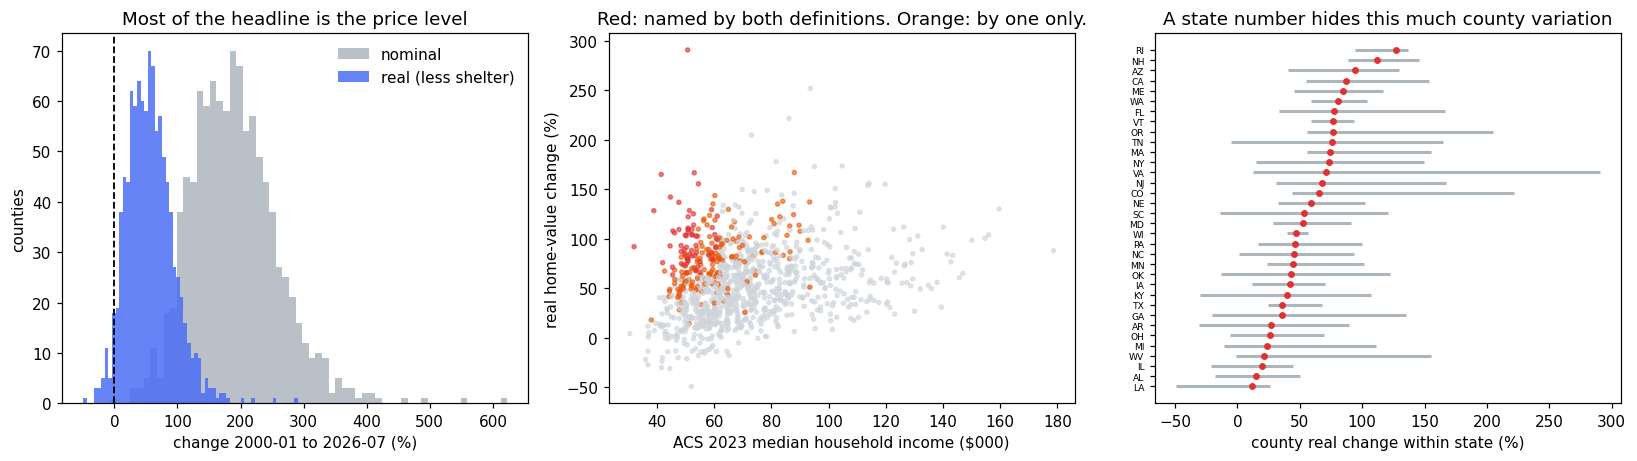

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

axes[0].hist(panel.nominal * 100, bins=60, alpha=.85, color="#adb5bd", label="nominal")
axes[0].hist(panel.real * 100, bins=60, alpha=.85, color="#4c6ef5", label="real (less shelter)")
axes[0].axvline(0, color="k", lw=1.2, ls="--")
axes[0].set_xlabel("change 2000-01 to 2026-07 (%)")
axes[0].set_ylabel("counties")
axes[0].set_title("Most of the headline is the price level")
axes[0].legend(frameon=False)

colour = np.where(national & within_state, "#e03131",
         np.where(national ^ within_state, "#e8590c", "#ced4da"))
axes[1].scatter(panel.median_income / 1000, panel.real * 100, s=7, c=colour, alpha=.6)
axes[1].set_xlabel("ACS 2023 median household income ($000)")
axes[1].set_ylabel("real home-value change (%)")
axes[1].set_title("Red: named by both definitions. Orange: by one only.")

state_spread = (panel.groupby("StateName").real
                .agg(["count", "min", "median", "max"])
                .query(f"count >= {MIN_COUNTIES_PER_STATE}")
                .sort_values("median"))
axes[2].hlines(range(len(state_spread)), state_spread["min"] * 100,
               state_spread["max"] * 100, color="#adb5bd", lw=2)
axes[2].plot(state_spread["median"] * 100, range(len(state_spread)), "o",
             ms=3.5, color="#e03131")
axes[2].set_yticks(range(len(state_spread)))
axes[2].set_yticklabels(state_spread.index, fontsize=6)
axes[2].set_xlabel("county real change within state (%)")
axes[2].set_title("A state number hides this much county variation")
plt.tight_layout(); plt.show()

## 4. The unit of analysis, which no amount of care fixes

The panel above on the right shows the spread of county outcomes inside a single state. A state
figure is an average over that spread, and reporting it alone would conceal counties moving in
opposite directions.

**The same relationship holds one level down, and that is where gentrification lives.** A county
contains neighbourhoods that appreciate and neighbourhoods that do not; the process the word names
is precisely the divergence between them. A county index is an average over exactly the variation
that constitutes the phenomenon.

This is not a precision problem that a larger sample or a tighter margin would solve. It is a
**construct** problem: the measure and the concept are defined at different scales. The
county-level statistic computed below is therefore reported as what it is — a measure of
**county-level home-value appreciation conditioned on baseline income** — and not as a measure of
gentrification.

What would be needed instead: ZHVI is published at ZIP and neighbourhood level, and ACS publishes
these tables at tract level. A defensible measure would pair tract-level ACS change with
neighbourhood-level price change, which is how the published literature does it. That is a
different acquisition and a different notebook, and it is named here rather than approximated.

In [9]:
# Spread is reported on the REAL series, because that is the quantity the
# surrounding argument is about. Computing it on nominal and describing it as
# real is the narrative-versus-computation defect this corpus gates against.
within = (panel.groupby("StateName").real
          .agg(n="count", lo="min", hi="max", med="median")
          .query(f"n >= {MIN_COUNTIES_PER_STATE}"))
within["spread_pp"] = (within.hi - within.lo) * 100

print(f"Within-state spread of county REAL home-value change ({len(within)} states)")
print(f"  median state's county spread : {within.spread_pp.median():.0f} pp")
print(f"  widest                       : {within.spread_pp.max():.0f} pp "
      f"({within.spread_pp.idxmax()})")
print(f"  narrowest                    : {within.spread_pp.min():.0f} pp "
      f"({within.spread_pp.idxmin()})")
print()
_signflip = within.query("lo < 0 < hi")
_verb = "state" if len(_signflip) == 1 else "states"
print(f"The clearest form of the problem is a state holding counties that moved in OPPOSITE")
print(f"directions in real terms: {len(_signflip)} of {len(within)} {_verb} span zero real change.")
_nom_within = (panel.groupby("StateName").nominal
               .agg(n="count", lo="min", hi="max")
               .query(f"n >= {MIN_COUNTIES_PER_STATE}"))
_nom_flip = int(((_nom_within.lo < 0) & (_nom_within.hi > 0)).sum())
print(f"For comparison, on the nominal series that count is {_nom_flip}: deflation is what")
print("makes the divergence visible, because nominal growth is almost never negative.")
print()
print("Read as an illustration of the mechanism, not as evidence about tracts: aggregation")
print("hides divergence, and the finer the process, the more it hides. Gentrification is")
print("defined at a scale below the one measured here.")

Within-state spread of county REAL home-value change (34 states)
  median state's county spread : 91 pp
  widest                       : 278 pp (VA)
  narrowest                    : 16 pp (WI)

The clearest form of the problem is a state holding counties that moved in OPPOSITE
directions in real terms: 12 of 34 states span zero real change.
For comparison, on the nominal series that count is 1: deflation is what
makes the divergence visible, because nominal growth is almost never negative.

Read as an illustration of the mechanism, not as evidence about tracts: aggregation
hides divergence, and the finer the process, the more it hides. Gentrification is
defined at a scale below the one measured here.


## Limitations

- **The unit of analysis does not match the construct.** Counties cannot resolve a neighbourhood
  process. Everything below is conditioned on that and no result here should be described as a
  gentrification measure.
- **The sample is selected, not random.** 32% of counties, holding 72% of occupied units. Counties
  without a 2000 ZHVI value are systematically smaller and more rural, and that is correlated with
  housing-market behaviour.
- **ZHVI is a modelled index, not transaction prices.** It is produced from Zillow's own valuation
  model, revised historically, and its methodology changed materially in 2023 with the neural
  Zestimate. A 2000–2026 series is therefore not a constant instrument.
- **ZORI covers 43.0% of counties and is not used for the headline** (measured in `data/zillow/2026-08/SOURCES.md`, not in this notebook) for that reason; any rent-side
  version of this analysis would carry a much heavier selection problem.
- **ACS income is a single 2023 cross-section, not a baseline.** A proper baseline-disadvantage
  condition would use income *at the start* of the window, from Census 2000. Using an endpoint
  measurement as a baseline condition conditions partly on the outcome.
- **A national deflator is applied to local prices.** Regional price levels differ and diverged
  over this window; CPI-U is a national index.
- **FRED series are revised.** These are values as served on the retrieval date, not a
  vintage-frozen ALFRED snapshot, so a re-run after a revision will differ slightly.
- **No causal claim is available.** Nothing here identifies why any county's values moved.

In [10]:
"""Findings. Every number below is rendered from a value computed above."""
analysis_units = acs.loc[acs.fips.isin(set(panel.fips)), "occupied_units"].sum() / total_units

print("FINDINGS")
print("=" * 78)
print(f"1. The analysis set is {len(panel):,} of {len(acs_fips):,} counties "
      f"({len(panel) / len(acs_fips):.1%}) but {analysis_units:.1%} of occupied")
print(f"   housing units. The sample is small in counties and large in households, so the two")
print(f"   framings support different sentences.")
print(f"2. Median county home value rose {panel.nominal.median():.1%} nominally and "
      f"{panel.real.median():.1%} in real terms;")
print(f"   {inflation_share:.0%} of the headline is the general price level. "
      f"{int((panel.real < 0).sum()):,} counties "
      f"({(panel.real < 0).mean():.1%}) are worth")
print(f"   LESS in real terms than in 2000.")
print(f"3. The deflator choice ({codes[0]} vs {codes[1]}) moves "
      f"{int(((panel[f'real_{codes[0]}'] < 0) != (panel[f'real_{codes[1]}'] < 0)).sum())} "
      f"counties across zero")
print(f"   and reorders none of them (largest rank move {int(moves.max())}). It governs the sign, "
      f"not the ranking.")
print(f"4. Holding thresholds identical and varying only the reference population, the two")
print(f"   definitions name {int(national.sum())} and {int(within_state.sum())} counties, agree on "
      f"{both}, and overlap at Jaccard {jaccard:.3f}.")
print(f"   Roughly {1 - jaccard:.0%} of the combined membership depends on that one choice.")
print(f"5. Within states, county REAL outcomes span a median of "
      f"{within.spread_pp.median():.0f} percentage points, and "
      f"{len(_signflip)} of {len(within)}")
print(f"   states hold counties that moved in opposite directions. Aggregation hides")
print(f"   divergence; gentrification is defined below the scale measured here.")
print("=" * 78)
print()
print("SCOPE. The statistic computed here is county-level home-value appreciation conditioned")
print("on baseline median income. It is not a measure of gentrification, and the difference is")
print("one of construct rather than precision.")

FINDINGS
1. The analysis set is 1,026 of 3,222 counties (31.8%) but 72.4% of occupied
   housing units. The sample is small in counties and large in households, so the two
   framings support different sentences.
2. Median county home value rose 185.6% nominally and 54.4% in real terms;
   71% of the headline is the general price level. 37 counties (3.6%) are worth
   LESS in real terms than in 2000.
3. The deflator choice (CPIAUCSL vs CUUR0000SA0L2) moves 20 counties across zero
   and reorders none of them (largest rank move 0). It governs the sign, not the ranking.
4. Holding thresholds identical and varying only the reference population, the two
   definitions name 124 and 161 counties, agree on 66, and overlap at Jaccard 0.301.
   Roughly 70% of the combined membership depends on that one choice.
5. Within states, county REAL outcomes span a median of 91 percentage points, and 12 of 34
   states hold counties that moved in opposite directions. Aggregation hides
   divergence; gent

## Key Takeaways

1. Ask whether the data can address the concept before asking whether the arithmetic is right. A
   flawless statistic at the wrong scale is still the wrong statistic.
2. Report a coverage cascade both ways. "32% of counties" and "72% of households" describe the same
   sample and license different claims.
3. Over long windows, deflate. Roughly three-quarters of a twenty-six-year nominal housing change
   here is the general price level, and a meaningful minority of places lost real value.
4. Choose the deflator on substance — excluding shelter avoids deflating housing by housing — and
   know its reach: a national deflator governs level and sign, never ranking.
5. When a construct has no agreed operationalisation, compute more than one and publish the
   disagreement. Two defensible definitions here overlap at Jaccard 0.30.
6. Say what the measure is not, in the artifact, as prominently as what it is. That sentence is the
   deliverable when the honest answer is that the question cannot be answered at this grain.

## Exercises

1. **Do it at the right scale.** Acquire ZIP-level ZHVI and tract-level ACS, pin them with
   `BulkFileSource`, and rebuild the measure where the construct actually lives. Report how many of
   the counties named above contain both gentrifying and declining tracts.
2. **A real baseline.** Replace the 2023 income cross-section with Census 2000 median income (SF3
   table P053). Does conditioning on a genuine baseline rather than an endpoint change which
   counties are named, and in which direction?
3. **The rent-side version, scoped.** Build the ZORI analogue on its 43%-coverage subset. Quantify
   how the covered counties differ from the excluded ones on income and density, and state what the
   result can be said about.
4. **Index instability.** ZHVI's methodology changed in 2023. Split the window at that boundary and
   check whether county rankings are stable across it. If they are not, what does a 2000–2026 growth
   figure mean?
5. **Regional price levels.** Replace the national deflator with BEA Regional Price Parities. Does
   the count of counties with negative real appreciation change materially, and which places move?
6. **Threshold surface.** Sweep both percentiles from 20 to 60 and map the number of counties named.
   Is there a stable plateau, or does the count vary smoothly with no defensible resting point?

## References

- Zillow Research. *Housing Data* — ZHVI and ZORI methodology and downloads.
  <https://www.zillow.com/research/data/>. Files pinned in `data/zillow/2026-08/SOURCES.md`.
- U.S. Census Bureau. *American Community Survey 2023 5-Year Estimates*, tables **B19013**,
  **B25003**.
- Federal Reserve Bank of St. Louis. *FRED* series **CPIAUCSL** and **CUUR0000SA0L2**.
- U.S. Bureau of Labor Statistics. *Consumer Price Index: relative importance of shelter in the
  CPI-U basket* — the basis for preferring the less-shelter series when deflating housing.
- Freeman, L. (2005). "Displacement or Succession? Residential Mobility in Gentrifying
  Neighborhoods." *Urban Affairs Review* 40(4), 463–491 — an operational definition at tract level.
- Ding, L., Hwang, J. and Divringi, E. (2016). "Gentrification and Residential Mobility in
  Philadelphia." *Regional Science and Urban Economics* 61, 38–51 — city-relative thresholds.
- Openshaw, S. (1984). *The Modifiable Areal Unit Problem*. CATMOG 38 — why a result computed at
  one geography need not survive at another.
- Zuk, M., Bierbaum, A. H., Chapple, K., et al. (2018). "Gentrification, Displacement, and the Role
  of Public Investment." *Journal of Planning Literature* 33(1), 31–44 — a review of how
  inconsistently the concept is operationalised.

In [11]:
"""Provenance for all four sources, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "08-culture-society/D27_housing_affordability_and_gentrification" / "provenance"
written = [
    prov_zhvi.write(out_dir / "d27g_zillow_zhvi_county.json"),
    prov_acs.write(out_dir / "d27g_acs_county.json"),
]
for _code, _prov in deflator_prov.items():
    written.append(_prov.write(out_dir / f"d27g_fred_{_code.lower()}.json"))

print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
print(f"ZHVI payload digest : {prov_zhvi.content_sha256[:16]}...  (pinned bulk file)")
print(f"ACS payload digest  : {prov_acs.content_sha256[:16]}...")
for _code, _prov in deflator_prov.items():
    print(f"{_code:<20}: {_prov.content_sha256[:16]}...")
print()
print(f"Analysis set        : {len(panel):,} counties")
print(f"Deflator used       : {DEFLATOR} ({DEFLATORS[DEFLATOR]})")

Provenance written:
  d27g_zillow_zhvi_county.json
  d27g_acs_county.json
  d27g_fred_cpiaucsl.json
  d27g_fred_cuur0000sa0l2.json

ZHVI payload digest : 01ccc62277cd314e...  (pinned bulk file)
ACS payload digest  : 53640b965552b248...
CPIAUCSL            : 2c46e179bc28c7e3...
CUUR0000SA0L2       : 43ce3ee22f0ca15c...

Analysis set        : 1,026 counties
Deflator used       : CUUR0000SA0L2 (CPI-U less shelter (the defensible choice for housing))
